# Лаб_3. RAG-поиск по корпусу нормативных актов

**Автор:** Алексеев Георгий Александрович M3412

## Тематика: законодательство о несостоятельности (банкротстве)

Строим конвейер Retrieval-Augmented Generation для правовой базы: сбор корпуса нормативных актов -> чанкинг двумя способами -> эмбеддинги и индекс FAISS -> очистка пользовательского запроса -> ответ LLM строго по найденным фрагментам со ссылками на акты -> количественная оценка поиска и генерации (вариант 2, RAGAS).

Предметная область - банкротство: федеральные законы, постановления Правительства, акты Конституционного Суда и ведомственные приказы. Здесь RAG особенно нужен: юристу важен точный текст нормы и ссылка на акт, а LLM `по памяти` легко путает номера статей и редакции.

## 0. Подготовка окружения

Импортируем библиотеки и настраиваем клиент LLM. Модель и ключ OpenAI-совместимого API читаются из `.env` (файл не попадает в git). Все тяжёлые шаги (корпус, эмбеддинги, ответы LLM) кешируются в `data/`, поэтому повторный запуск ноутбука занимает минуты.

In [1]:
import os, re, json, time, random, hashlib, asyncio, threading
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import faiss
from dotenv import load_dotenv
from openai import OpenAI, AsyncOpenAI
from IPython.display import display, Markdown

RND = 42
random.seed(RND); np.random.seed(RND)
DATA = Path("data"); DATA.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

load_dotenv(".env")
LLM_MODEL = os.environ.get("LLM_MODEL", "gpt-6-luna")
client = OpenAI(base_url=os.environ["LLM_BASE_URL"], api_key=os.environ["LLM_API_KEY"])

pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid")
print(f"device: {DEVICE}, LLM: {LLM_MODEL}")

device: cuda, LLM: gpt-6-luna


## 1. Сбор корпуса документов

Источник - открытый датасет **RusLawOD** (HuggingFace, `irlspbru/RusLawOD`): ~310 тыс. актов с официального портала pravo.gov.ru с метаданными (название, орган, дата, номер, вид акта, статус) и полным текстом. Датасет лежит в 11 parquet-файлах по ~600 МБ, поэтому целиком его не качаем:

1. По каждому файлу читаем по сети **только колонки метаданных** (parquet позволяет читать отдельные колонки) и отбираем акты, у которых в названии или ключевых словах есть `банкрот` / `несостоятельн`;
2. Отбрасываем процедурные акты палат парламента (`принять в первом чтении`, `одобрить`) и распоряжения о составах комиссий - в них почти нет нормативного текста; кодексы и бюджетные законы отсекаются ограничением длины;
3. Для отобранных строк дочитываем колонку с текстом.

Каждое сетевое чтение обёрнуто в повтор с экспоненциальной паузой. Сырая выборка кешируется в `data/raw/`, итоговый корпус (метаданные + очищенный текст) сохраняется в `data/corpus.jsonl`.

In [2]:
from huggingface_hub import HfFileSystem
import pyarrow.parquet as pq

HF_REPO = "datasets/irlspbru/RusLawOD"
N_FILES = 11
META_COLS = ["pravogovruNd", "issuedByIPS", "docdateIPS", "docNumberIPS", "doc_typeIPS",
             "headingIPS", "statusIPS", "keywordsByIPS"]
THEME = r"банкрот|несостоятельн"
PROCEDURAL = r"Государственной Думы|Совета Федерации|Распоряжение Правительства|Верховного Совета|Президиума"
CORE_LAW = "102078527"            # 127-ФЗ `О несостоятельности (банкротстве)` - берём, несмотря на длину
MIN_WORDS, MAX_WORDS = 150, 25000


def with_retries(fn, attempts=4, delay=3):
    """Повтор сетевого вызова с экспоненциальной паузой."""
    for i in range(attempts):
        try:
            return fn()
        except Exception as e:
            if i == attempts - 1:
                raise
            print(f"  сбой: {type(e).__name__}, повтор через {delay * 2 ** i} с")
            time.sleep(delay * 2 ** i)


def read_columns(file_no, columns):
    fs = HfFileSystem()
    def _read():
        with fs.open(f"{HF_REPO}/ruslawod_{file_no:02d}.parquet", "rb") as f:
            return pq.ParquetFile(f).read(columns=columns)
    return with_retries(_read)

### Очистка текста

Тексты из ИПС содержат артефакты HTML-разметки. Правила очистки повторяют нормализацию из рабочего проекта Legal-RAG:
- удаляем теги `<ref nd=...>` и `<p class=...>`;
- вырезаем перечни публикаций `(Собрание законодательства Российской Федерации, 2002, № 43, ст. 4190; ...)` - это шум, который забивает чанки цифрами;
- восстанавливаем номера статей, разорванные надстрочным индексом: `Статья 61 2 .` -> `Статья 61.2.`;
- схлопываем пробелы и пустые строки.

In [3]:
TAG_RE = re.compile(r"<[^>]+>")
PUBL_RE = re.compile(r"\s*\((?:Собрание законодательства|Ведомости|Российская газета)[^()]*(?:\([^()]*\)[^()]*)*\)")
SPACED_ART_RE = re.compile(r"(?m)^(Статья\s+)(\d+(?:\.\d+)*)((?:\s+\d+(?:-\d+)*)+)\s*\.")


def clean_text(text):
    text = TAG_RE.sub(" ", text or "").replace("\xa0", " ")
    text = PUBL_RE.sub("", text)
    lines = (re.sub(r"[ \t]{2,}", " ", ln).strip() for ln in text.splitlines())
    text = "\n".join(ln for ln in lines if ln)
    return SPACED_ART_RE.sub(lambda m: m[1] + ".".join([m[2], *m[3].split()]) + ".", text)


def short_issuer(s):
    for key, short in [("Федеральный закон", "Федеральный закон"), ("Постановление Правительства", "Постановление Правительства"),
                       ("Конституционного Суда", "Конституционный Суд"), ("Указ Президента", "Указ Президента"),
                       ("Приказ", "Приказ ведомства"), ("Закон", "Закон РФ/РСФСР")]:
        if key in s:
            return short
    return "Прочее"


print(clean_text('Статья 61 2 . Оспаривание <ref nd="1">сделок</ref> (Собрание законодательства РФ, 2002, № 43, ст. 4190)'))

Статья 61.2. Оспаривание сделок


In [4]:
RAW_PATH = DATA / "raw" / "ruslawod_bankruptcy.parquet"
CORPUS_PATH = DATA / "corpus.jsonl"

if RAW_PATH.exists():
    raw = pd.read_parquet(RAW_PATH)
else:
    parts = []
    for i in range(1, N_FILES + 1):
        meta = read_columns(i, META_COLS).to_pandas()
        meta["row"] = np.arange(len(meta))
        on_topic = (meta.headingIPS.str.contains(THEME, case=False, na=False)
                    | meta.keywordsByIPS.str.contains(THEME, case=False, na=False))
        sel = meta[on_topic & ~meta.issuedByIPS.str.contains(PROCEDURAL, na=False)
                   & (meta.doc_typeIPS != "Кодекс")].copy()
        texts = read_columns(i, ["textIPS"]).column(0)
        sel["raw_text"] = [texts[r].as_py() for r in sel.row]
        parts.append(sel)
        print(f"файл {i:02d}: {len(meta)} актов, по теме {len(sel)}")
    raw = pd.concat(parts, ignore_index=True)
    RAW_PATH.parent.mkdir(exist_ok=True)
    raw.to_parquet(RAW_PATH)

corpus = pd.DataFrame({
    "doc_id": "pravo:" + raw.pravogovruNd,
    "nd": raw.pravogovruNd,
    "title": raw.headingIPS.str.strip(),
    "issued_by": raw.issuedByIPS.str.strip(),
    "issuer": raw.issuedByIPS.fillna("").map(short_issuer),
    "number": raw.docNumberIPS,
    "date": raw.docdateIPS,
    "year": pd.to_datetime(raw.docdateIPS, format="%d.%m.%Y", errors="coerce").dt.year,
    "status": raw.statusIPS,
    "url": "http://pravo.gov.ru/proxy/ips/?docbody=&nd=" + raw.pravogovruNd,
    "text": raw.raw_text.map(clean_text),
})
corpus["n_words"] = corpus.text.str.split().str.len()
corpus = corpus[corpus.n_words.between(MIN_WORDS, MAX_WORDS) | (corpus.nd == CORE_LAW)]
corpus = (corpus.drop_duplicates("nd").drop_duplicates("text")
                .sort_values(["year", "doc_id"]).reset_index(drop=True))
corpus.to_json(CORPUS_PATH, orient="records", lines=True, force_ascii=False)

print(f"Документов: {len(corpus)}, годы {corpus.year.min()}-{corpus.year.max()}, "
      f"слов всего: {corpus.n_words.sum():,}")
corpus[["doc_id", "title", "issuer", "date", "status", "n_words"]].sample(6, random_state=RND)

Документов: 410, годы 1990-2026, слов всего: 1,638,823


,doc_id,title,issuer,date,status,n_words
172,pravo:102158456,О внесении изменений в отдельные законодательные акты Российской Федерации,Федеральный закон,28.07.2012,Действует с изменениями,9001
137,pravo:102123535,О содействии развитию жилищного строительства,Федеральный закон,24.07.2008,Действует с изменениями,8803
126,pravo:102109145,О порядке взаимодействия федеральных органов исполнительной власти при подготовке предложений по формирова...,Постановление Правительства,02.10.2006,Действует с изменениями,1399
94,pravo:102088201,"О реструктуризации в 2004 году задолженности по государственным кредитам, полученным в 1992-1998 годах суб...",Постановление Правительства,07.08.2004,Действует без изменений,2843
72,pravo:102096073,"Об утверждении разъяснения о вопросах, связанных с применением процедур банкротства",Прочее,14.06.2002,Действует без изменений,363
33,pravo:102060919,О реструктуризации кредитных организаций,Федеральный закон,08.07.1999,Утратил силу,7234


### Обзор корпуса

Смотрим состав по видам актов, по годам и распределение длины текстов.

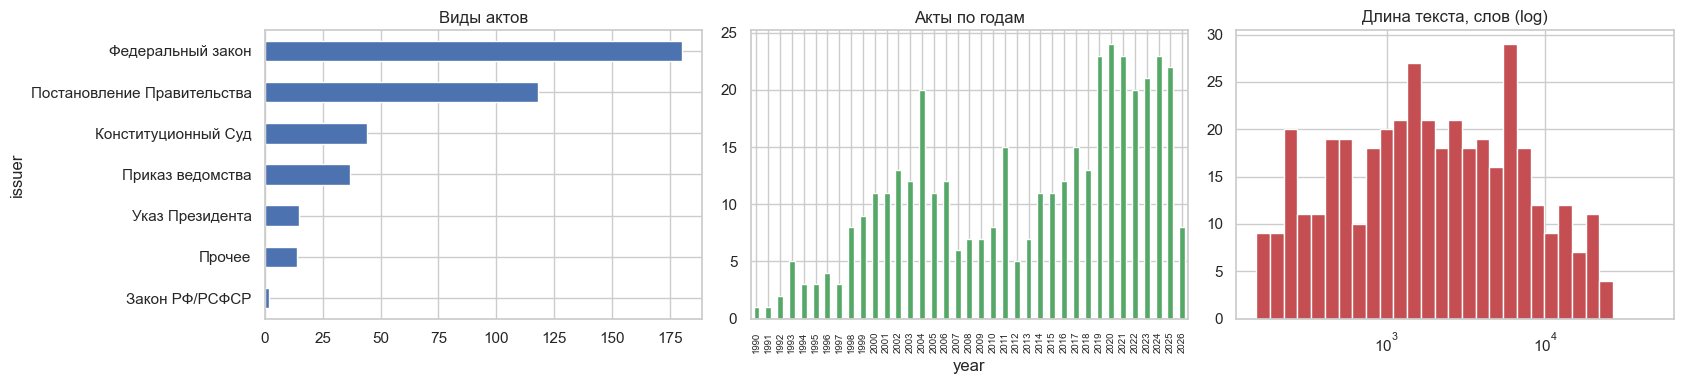

{'count': 410.0, 'mean': 3997.0, 'std': 5370.0, 'min': 163.0, '25%': 675.0, '50%': 1844.0, '75%': 5442.0, 'max': 48854.0}


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
corpus.issuer.value_counts().sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Виды актов")
corpus.year.value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868")
ax[1].set_title("Акты по годам"); ax[1].tick_params(axis="x", labelsize=7)
ax[2].hist(corpus.n_words, bins=np.logspace(np.log10(150), np.log10(corpus.n_words.max()), 30), color="#C44E52")
ax[2].set_xscale("log"); ax[2].set_title("Длина текста, слов (log)")
plt.tight_layout(); plt.show()
print(corpus.n_words.describe().round(0).to_dict())

## 2. Препроцессинг и чанкинг

Единый документ = **название акта + текст** (название идёт первой строкой, поэтому попадает в первый чанк). Аннотаций у нормативных актов нет, и тексты длиннее научных аннотаций в десятки раз, поэтому разбиение на смысловые фрагменты здесь критично.

Параметры окна: **~140 слов** с перекрытием **~25 слов**. Это ~1-2 пункта статьи: достаточно, чтобы фрагмент был самодостаточной нормой, и не слишком много, чтобы эмбеддинг не `размазывался` по нескольким темам.

### 2.1. Чанкинг на чистом Python (с учётом структуры акта)

Сначала режем текст на **структурные разделы** по заголовкам `Статья N`, `Глава`, `Раздел`, по пунктам подзаконных актов `1. Текст` и по `Приложение`/`УТВЕРЖДЕН` (правила из Legal-RAG). Слишком мелкие разделы (< 40 слов) приклеиваем к следующему. Внутри раздела идём **скользящим окном по предложениям**: копим предложения до 140 слов, следующий чанк начинаем с хвоста предыдущего в 25 слов. Чанк никогда не пересекает границу статьи, а к нему сохраняется заголовок раздела.

In [6]:
CHUNK_WORDS, OVERLAP_WORDS, MIN_SECTION_WORDS = 140, 25, 40
SECTION_START = re.compile(r"(?m)^(?=(?:Статья|Глава|ГЛАВА|Раздел|РАЗДЕЛ)\s+[\dIVXLC]|\d{1,3}\.\s+[А-ЯЁ]|УТВЕРЖДЕН|Приложение)")
SENT_SPLIT = re.compile(r"(?<=[.;:!?])\s+(?=[А-ЯЁ0-9«\"(])")


def split_sections(text):
    sections = []
    for part in (p.strip() for p in SECTION_START.split(text)):
        if not part:
            continue
        if sections and len(sections[-1].split()) < MIN_SECTION_WORDS:
            sections[-1] += "\n" + part
        else:
            sections.append(part)
    return sections


def window_chunks(section, size=CHUNK_WORDS, overlap=OVERLAP_WORDS):
    units = []                                   # предложения; слишком длинные режем по словам
    for s in SENT_SPLIT.split(section):
        w = s.split()
        units += [" ".join(w[i:i + size]) for i in range(0, len(w), size)] if len(w) > size else [s]
    chunks, cur = [], []
    for u in units:
        if cur and len(" ".join(cur).split()) + len(u.split()) > size:
            chunks.append(" ".join(cur))
            cur = [" ".join(chunks[-1].split()[-overlap:])]     # перекрытие - хвост предыдущего окна
        cur.append(u)
    if cur:
        tail = " ".join(cur)
        if chunks and len(tail.split()) < 2 * overlap:          # короткий остаток не делаем отдельным чанком
            chunks[-1] += " " + " ".join(tail.split()[overlap:])
        else:
            chunks.append(tail)
    return chunks


def chunk_python(doc):
    rows = []
    for section in split_sections(doc.title + "\n" + doc.text):
        heading = section.split("\n", 1)[0][:120]
        for text in window_chunks(section.replace("\n", " ")):
            if rows and len(text.split()) < 20:                 # обрывок раздела приклеиваем к предыдущему чанку
                rows[-1]["text"] += " " + text
                rows[-1]["n_words"] = len(rows[-1]["text"].split())
                continue
            rows.append({"chunk_id": f"{doc.doc_id}#py{len(rows)}", "doc_id": doc.doc_id, "title": doc.title,
                         "issued_by": doc.issued_by, "date": doc.date, "url": doc.url,
                         "section": heading, "text": text, "n_words": len(text.split())})
    return rows


chunks_py = pd.DataFrame([r for doc in corpus.itertuples() for r in chunk_python(doc)])
print(f"Чанков: {len(chunks_py)}")
chunks_py[chunks_py.doc_id == corpus.doc_id.iloc[200]].head(3)[["chunk_id", "section", "n_words", "text"]]

Чанков: 19269


,chunk_id,section,n_words,text
9175,pravo:102375692#py0,О внесении изменений в отдельные законодательные акты Российской Федерации,116,О внесении изменений в отдельные законодательные акты Российской Федерации РОССИЙСКАЯ ФЕДЕРАЦИЯ ФЕДЕРАЛЬНЫ...
9176,pravo:102375692#py1,Статья 2,64,"Статья 2 Внести в Федеральный закон от 26 октября 2002 года № 127-ФЗ ""О несостоятельности (банкротстве)"" с..."
9177,pravo:102375692#py2,Статья 3,59,"Статья 3 В части 13 статьи 36 Федерального закона от 23 декабря 2003 года № 177-ФЗ ""О страховании вкладов ..."


### 2.2. Чанкинг через `RecursiveCharacterTextSplitter` (LangChain)

Сплиттер работает в символах, поэтому переводим 140/25 слов в символы через среднюю длину слова в корпусе. Разделители идут от крупных к мелким: начало статьи, абзац, строка, предложение, слово. О структуре акта сплиттер не знает - заголовок статьи может оказаться в середине чанка, а чанк - захватить конец одной статьи и начало другой.

In [7]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

chars_per_word = corpus.text.str.len().sum() / corpus.n_words.sum()
splitter = RecursiveCharacterTextSplitter(
    chunk_size=round(CHUNK_WORDS * chars_per_word), chunk_overlap=round(OVERLAP_WORDS * chars_per_word),
    separators=["\nСтатья ", "\n\n", "\n", ". ", " ", ""], keep_separator=True)

rows = []
for doc in corpus.itertuples():
    for i, text in enumerate(splitter.split_text(doc.title + "\n" + doc.text)):
        text = " ".join(text.split())
        rows.append({"chunk_id": f"{doc.doc_id}#lc{i}", "doc_id": doc.doc_id, "title": doc.title,
                     "issued_by": doc.issued_by, "date": doc.date, "url": doc.url,
                     "section": "", "text": text, "n_words": len(text.split())})
chunks_lc = pd.DataFrame(rows)
chunks_lc = chunks_lc[chunks_lc.n_words >= 5].reset_index(drop=True)      # отбрасываем обрывки вида `Статья 5.`
print(f"символов на слово: {chars_per_word:.2f} -> chunk_size={splitter._chunk_size}, overlap={splitter._chunk_overlap}")
print(f"Чанков: {len(chunks_lc)}")

символов на слово: 8.11 -> chunk_size=1135, overlap=203
Чанков: 16425


### Сравнение двух стратегий

Сравниваем число и длину чанков. У каждого чанка есть метаданные родительского акта: `doc_id`, название, орган (аналог авторов), дата и ссылка на pravo.gov.ru.

,count,mean,std,min,25%,50%,75%,max
py,19269.0,97.0,35.1,20.0,66.0,99.0,127.0,189.0
lc,16425.0,105.8,32.0,5.0,87.0,113.0,129.0,260.0


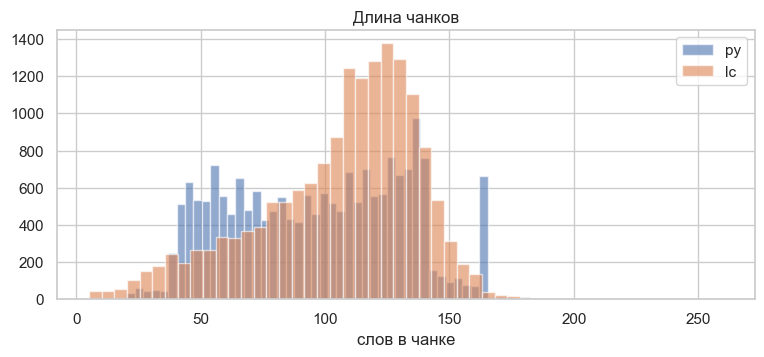

{'chunk_id': 'pravo:102051516#py119',
 'doc_id': 'pravo:102051516',
 'title': 'Об обществах с ограниченной ответственностью',
 'issued_by': 'Федеральный закон',
 'date': '08.02.1998',
 'url': 'http://pravo.gov.ru/proxy/ips/?docbody=&nd=102051516',
 'section': '3. Порядок проведения заочного голосования определяется внутренним документом общества, который должен предусматривать о',
 'text': '3. Порядок проведения заочного голосования определяется внутренним документом общества, который должен предусматривать обязательность сообщения всем участникам общества предлагаемой повестки дня, возможность ознакомления всех участников общества до начала голосования со всеми необходимыми информацией и материалами, возможность вносить предложения о включении в повестку дня дополнительных вопросов, обязательность сообщения всем участникам общества до начала голосования измененной повестки дня, а также срок окончания процедуры голосования.',
 'n_words': 61}

In [8]:
CHUNKS = {"py": chunks_py, "lc": chunks_lc}
for name, ch in CHUNKS.items():
    ch.to_json(DATA / f"chunks_{name}.jsonl", orient="records", lines=True, force_ascii=False)

display(pd.DataFrame({name: ch.n_words.describe().round(1) for name, ch in CHUNKS.items()}).T)
plt.figure(figsize=(9, 3.5))
for name, ch in CHUNKS.items():
    plt.hist(ch.n_words.clip(upper=260), bins=50, alpha=0.6, label=name)
plt.xlabel("слов в чанке"); plt.legend(); plt.title("Длина чанков"); plt.show()
chunks_py.iloc[1000].to_dict()

## 3. Векторизация и индекс FAISS

Эмбеддинги строим моделью **`Roflmax/bge-m3-legal-ru`** - это BGE-M3, дообученная на российских правовых текстах (её же использует Legal-RAG). Размерность 1024, векторы **L2-нормализуются**, поэтому скалярное произведение в `IndexFlatIP` равно косинусному сходству. Индекс точный (полный перебор): при ~10 тыс. векторов поиск занимает миллисекунды.

Индексы строятся отдельно для каждой стратегии чанкинга. Эмбеддинги кешируются в `data/emb_*.npy`.

In [9]:
from sentence_transformers import SentenceTransformer

EMB_MODEL = "Roflmax/bge-m3-legal-ru"
encoder = SentenceTransformer(EMB_MODEL, device=DEVICE,
                              model_kwargs={"dtype": torch.float16} if DEVICE == "cuda" else {})
encoder.max_seq_length = 512


def embed(texts, batch_size=32):
    return encoder.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False).astype("float32")


INDEX = {}
for name, ch in CHUNKS.items():
    path = DATA / f"emb_{name}.npy"
    E = np.load(path) if path.exists() else None
    if E is None or len(E) != len(ch):
        t = time.time(); E = embed(ch.text); np.save(path, E)
        print(f"{name}: эмбеддинги за {time.time() - t:.0f} с")
    faiss.normalize_L2(E)
    INDEX[name] = faiss.IndexFlatIP(E.shape[1]); INDEX[name].add(E)
    print(f"{name}: {INDEX[name].ntotal} векторов, dim={E.shape[1]}, |v|={np.linalg.norm(E[:3], axis=1).round(3)}")

You are trying to use a model that was created with Sentence Transformers version 5.1.2, but you're currently using version 4.1.0. This might cause unexpected behavior or errors. In that case, try to update to the latest version.


py: 19269 векторов, dim=1024, |v|=[1. 1. 1.]
lc: 16425 векторов, dim=1024, |v|=[1. 1. 1.]


### Функция `retrieve`

Возвращает `top_k` ближайших чанков с косинусным сходством и метаданными родительского акта. `retrieve_many` - то же самое пачкой запросов (нужно для оценки).

In [10]:
def retrieve_many(queries, top_k=5, method="py"):
    scores, ids = INDEX[method].search(embed(queries), top_k)
    out = []
    for sc, ix in zip(scores, ids):
        res = CHUNKS[method].iloc[ix].copy()
        res.insert(0, "score", sc)
        out.append(res)
    return out


def retrieve(query, top_k=5, method="py"):
    return retrieve_many([query], top_k, method)[0]


retrieve("какие сделки должника можно оспорить в деле о банкротстве", 5)[["score", "title", "section", "text"]]

,score,title,section,text
8365,0.528859,"О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)"" и отдельные законодательные а...",3. Заявление об оспаривании сделки должника-гражданина по указанным в пункте 1 настоящей статьи основаниям...,3. Заявление об оспаривании сделки должника-гражданина по указанным в пункте 1 настоящей статьи основаниям...
5544,0.522076,О внесении изменений в отдельные законодательные акты Российской Федерации,Статья 61.4. Особенности оспаривания отдельных сделок должника,"Статья 61.4. Особенности оспаривания отдельных сделок должника 1. Сделки, совершаемые на биржевых торгах, ..."
5545,0.513132,О внесении изменений в отдельные законодательные акты Российской Федерации,"3. Сделки должника, направленные на исполнение обязательств, по которым должник получил равноценное встреч...","3. Сделки должника, направленные на исполнение обязательств, по которым должник получил равноценное встреч..."
5555,0.510852,О внесении изменений в отдельные законодательные акты Российской Федерации,"4. Кредиторы или иные лица, в отношении которых совершена оспариваемая сделка или о правах и об обязанност...","4. Кредиторы или иные лица, в отношении которых совершена оспариваемая сделка или о правах и об обязанност..."
15326,0.502510,по делу о проверке конституционности положений пункта 1 статьи 61-2 и пункта 11 статьи 189-40 Федерального...,"3. Возврат в конкурсную массу имущества, отчужденного должником по сделке, признанной недействительной на ...","зачастую не сопоставима с размером задолженности, их реализация позволяет погасить по крайней мере ее част..."


### Гибридный поиск (BM25 + dense, RRF)

В рабочем проекте Legal-RAG поиск гибридный: лексический BM25 ловит точные номера статей и редкие термины, плотный поиск - смысл. Результаты сливаются по **Reciprocal Rank Fusion** (`k=60`): `score = Σ 1/(60 + rank)`. Повторяем это для чанков 2.1 и в п. 6 сравним с чистым dense-поиском. Для BM25 слова стеммируются (Snowball), токены с цифрами (`61.2`, `127-фз`) не трогаются.

In [11]:
from rank_bm25 import BM25Okapi
from nltk.stem.snowball import SnowballStemmer

stemmer = SnowballStemmer("russian")
TOKEN_RE = re.compile(r"[а-яa-z0-9]+(?:[.\-][а-яa-z0-9]+)*")


def bm25_tokens(text):
    return [t if any(c.isdigit() for c in t) else stemmer.stem(t)
            for t in TOKEN_RE.findall(text.lower().replace("ё", "е"))]


bm25 = BM25Okapi([bm25_tokens(t) for t in chunks_py.text])


def retrieve_bm25(query, top_k=5):
    scores = bm25.get_scores(bm25_tokens(query))
    best = np.argsort(-scores)[:top_k]
    res = chunks_py.iloc[best].copy()
    res.insert(0, "score", scores[best])
    return res


def retrieve_hybrid(query, top_k=5, pool=50, k_rrf=60):
    dense = retrieve(query, pool, "py").index
    sparse = np.argsort(-bm25.get_scores(bm25_tokens(query)))[:pool]
    rrf = Counter()
    for ranking in (dense, sparse):
        for rank, i in enumerate(ranking):
            rrf[i] += 1 / (k_rrf + rank + 1)
    best = [i for i, _ in rrf.most_common(top_k)]
    res = chunks_py.loc[best].copy()
    res.insert(0, "score", [rrf[i] for i in best])
    return res


retrieve_hybrid("ст. 61.2 недействительность подозрительной сделки", 5)[["score", "title", "section"]]

,score,title,section
15348,0.031754,по делу о проверке конституционности положений пункта 1 статьи 61-2 и пункта 11 статьи 189-40 Федерального...,"1. Признать положения пункта 1 статьи 61 2 и пункта 11 статьи 189 40 Федерального закона ""О несостоятельно..."
5536,0.030886,О внесении изменений в отдельные законодательные акты Российской Федерации,Статья 61.2. Оспаривание подозрительных сделок должника
15325,0.030159,по делу о проверке конституционности положений пункта 1 статьи 61-2 и пункта 11 статьи 189-40 Федерального...,"3. Возврат в конкурсную массу имущества, отчужденного должником по сделке, признанной недействительной на ..."
5538,0.030018,О внесении изменений в отдельные законодательные акты Российской Федерации,"2. Сделка, совершенная должником в целях причинения вреда имущественным правам кредиторов, может быть приз..."
5552,0.026145,О внесении изменений в отдельные законодательные акты Российской Федерации,Статья 61.7. Отказ в оспаривании сделок должника


## 4. Обработка пользовательских запросов

Пользователь пишет с опечатками и сокращениями. Пайплайн очистки:

1. **Нормализация**: схлопываем пробелы, убираем мусорные символы.
2. **Исправление опечаток SymSpell**. Словарь строится по самому корпусу (все словоформы актов с частотами), поэтому юридические термины (`субсидиарной`, `конкурсный`, `реструктуризации`) в нём есть и не `исправляются` в бытовые слова. Слово меняется, только если его нет в словаре; среди кандидатов на минимальном расстоянии берётся самый частый. Если кандидат - другая форма того же слова (совпадает основа по стеммеру Snowball: `водителю` -> `водителя`), это не опечатка, а форма, которой просто нет в актах, и слово остаётся как есть.
3. **Защита терминов**: не трогаем токены с цифрами (`61.2`, `127-ФЗ`), аббревиатуры (2+ заглавных: `ГК`, `КоАП`, `ЕФРСБ`), латиницу и слова короче 4 букв (`ст`, `п`, `ч`).
4. **Раскрытие сокращений** (как в Legal-RAG): `ГК РФ` -> `ГК РФ (Гражданский кодекс Российской Федерации)` - в текстах актов кодексы названы полностью, и без расшифровки у запроса и чанка нет общих слов.

In [12]:
from symspellpy import SymSpell, Verbosity

sym = SymSpell(max_dictionary_edit_distance=2, prefix_length=7)
vocab = Counter(w for t in pd.concat([corpus.title, corpus.text])
                for w in re.findall(r"[а-я]+", t.lower().replace("ё", "е")))
for w, f in vocab.items():
    if len(w) > 1:
        sym.create_dictionary_entry(w, f)

ABBREV = {
    "закон о банкротстве": "Федеральный закон «О несостоятельности (банкротстве)»",
    "127-ФЗ": "Федеральный закон «О несостоятельности (банкротстве)»",
    "ГК РФ": "Гражданский кодекс Российской Федерации",
    "АПК РФ": "Арбитражный процессуальный кодекс Российской Федерации",
    "НК РФ": "Налоговый кодекс Российской Федерации",
    "КоАП РФ": "Кодекс Российской Федерации об административных правонарушениях",
    "ТК РФ": "Трудовой кодекс Российской Федерации",
    "УК РФ": "Уголовный кодекс Российской Федерации",
    "КС РФ": "Конституционный Суд Российской Федерации",
    "ВС РФ": "Верховный Суд Российской Федерации",
    "ЕФРСБ": "Единый федеральный реестр сведений о банкротстве",
    "СРО": "саморегулируемая организация арбитражных управляющих",
}
CYR_WORD = re.compile(r"[А-Яа-яЁё]+")


def fix_word(m, changes):
    w = m.group(0)
    lw = w.lower().replace("ё", "е")
    if len(w) <= 3 or sum(c.isupper() for c in w) >= 2 or lw in sym.words:
        return w
    sugg = sym.lookup(lw, Verbosity.CLOSEST, max_edit_distance=1 if len(lw) <= 5 else 2)
    if not sugg or stemmer.stem(sugg[0].term) == stemmer.stem(lw):   # нет кандидата или это другая словоформа
        return w
    fixed = sugg[0].term.capitalize() if w[0].isupper() else sugg[0].term
    changes.append(f"{w} -> {fixed}")
    return fixed


def clean_query(query, verbose=False):
    q = re.sub(r"[^\w\s.,;:!?()«»\"№§/-]", " ", query)
    q = re.sub(r"\s+", " ", q).strip()
    changes = []
    q = CYR_WORD.sub(lambda m: fix_word(m, changes), q)
    for abbr in sorted(ABBREV, key=len, reverse=True):
        pat = re.compile(rf"(?<![\w-]){re.escape(abbr)}(?![\w-])", re.IGNORECASE)
        if pat.search(q) and ABBREV[abbr].lower() not in q.lower():
            q = pat.sub(lambda m: f"{m.group(0)} ({ABBREV[abbr]})", q, count=1)
            changes.append(f"{abbr} -> расшифровка")
    return (q, changes) if verbose else q


print(f"Словарь SymSpell: {len(sym.words):,} словоформ")
examples = [
    "как оспорить сделку должнка по ст. 61.2 закона о банкротсве",
    "субсидиарная отвественность контролирующих лиц по 127-ФЗ",
    "реструктуризацыя долгов гражданина и рализация имущества",
    "публикация сведений в ЕФРСБ арбитражным управляюшим",
    "требования к СРО и ответственность по КоАП РФ",
]
pd.DataFrame([(q, *clean_query(q, verbose=True)) for q in examples], columns=["запрос", "очищенный", "правки"])

Словарь SymSpell: 30,428 словоформ


,запрос,очищенный,правки
0,как оспорить сделку должнка по ст. 61.2 закона о банкротсве,как оспорить сделку должника по ст. 61.2 закона о банкротстве,"[должнка -> должника, банкротсве -> банкротстве]"
1,субсидиарная отвественность контролирующих лиц по 127-ФЗ,субсидиарная ответственность контролирующих лиц по 127-ФЗ (Федеральный закон «О несостоятельности (банкрот...,"[отвественность -> ответственность, 127-ФЗ -> расшифровка]"
2,реструктуризацыя долгов гражданина и рализация имущества,реструктуризация долгов гражданина и реализация имущества,"[реструктуризацыя -> реструктуризация, рализация -> реализация]"
3,публикация сведений в ЕФРСБ арбитражным управляюшим,публикация сведений в ЕФРСБ (Единый федеральный реестр сведений о банкротстве) арбитражным управляющим,"[управляюшим -> управляющим, ЕФРСБ -> расшифровка]"
4,требования к СРО и ответственность по КоАП РФ,требования к СРО (саморегулируемая организация арбитражных управляющих) и ответственность по КоАП РФ (Коде...,"[КоАП РФ -> расшифровка, СРО -> расшифровка]"


Проверим, как очистка влияет на выдачу: для запроса с опечатками сравниваем top-3 до и после.

In [13]:
q = "реструктуризацыя долгов гражданена и плон рестуктуризации"
for label, text in [("исходный", q), ("очищенный", clean_query(q))]:
    print(f"{label}: {text}")
    display(retrieve(text, 3)[["score", "title", "section"]])

исходный: реструктуризацыя долгов гражданена и плон рестуктуризации


,score,title,section
8163,0.597207,"О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)"" и отдельные законодательные а...",Статья 1
8846,0.578327,Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и города фед...,"2. Срок реализации плана реструктуризации долгов гражданина не может быть более чем три года. В случае, ес..."
8293,0.573731,"О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)"" и отдельные законодательные а...","2. Срок реализации плана реструктуризации долгов гражданина не может быть более чем три года. В случае, ес..."


очищенный: реструктуризация долгов гражданина и план реструктуризации


,score,title,section
8846,0.669904,Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и города фед...,"2. Срок реализации плана реструктуризации долгов гражданина не может быть более чем три года. В случае, ес..."
8293,0.665650,"О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)"" и отдельные законодательные а...","2. Срок реализации плана реструктуризации долгов гражданина не может быть более чем три года. В случае, ес..."
8850,0.656423,Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и города фед...,5. План реструктуризации долгов гражданина должен предусматривать погашение требований конкурсных кредитор...


## 5. Интеграция с LLM и промпт-инжиниринг

Генерация - через OpenAI-совместимый API, модель `gpt-6-luna`. Найденные фрагменты подаются в контекст пронумерованными блоками `[n] Название акта (орган, дата)`. Требования системного промпта:
- отвечать **только** по контексту, не дописывать сведения из `памяти` модели (номера статей, сроки, суммы);
- после каждого утверждения ставить ссылку `[n]`, в конце - список источников с названиями актов;
- если ответа в контексте нет - ровно фраза `Информация в найденных статьях отсутствует`;
- учитывать дату акта: тексты в корпусе - в редакции на дату принятия.

Ответы LLM кешируются по хешу запроса в `data/llm_cache.json`.

In [14]:
NO_ANSWER = "Информация в найденных статьях отсутствует"

SYSTEM_PROMPT = f"""Ты - юридический ассистент по законодательству Российской Федерации о несостоятельности (банкротстве).
Отвечай на вопрос пользователя СТРОГО на основе фрагментов нормативных актов из блока КОНТЕКСТ.

Правила:
1. Используй только сведения из контекста. Не добавляй ничего из собственных знаний: не придумывай номера статей, сроки, суммы, названия актов.
2. После каждого утверждения ставь ссылку на фрагмент в квадратных скобках: [1], [2]. Если вывод опирается на несколько фрагментов - [1][3].
3. Если в контексте нет ответа на вопрос или фрагменты не относятся к вопросу, ответь ровно одной фразой: «{NO_ANSWER}».
4. Если ответ есть только частично - ответь на подтверждённую часть и прямо скажи, чего в найденных документах нет.
5. Учитывай дату акта: текст приведён в редакции на дату принятия, более поздний акт может менять более ранний.
6. В конце ответа (если ответ не отказ) дай список «Источники:» - [n] название акта, орган, дата - только для использованных фрагментов.
Отвечай по-русски, кратко и по существу."""

BASELINE_PROMPT = "Ты - юридический ассистент по законодательству Российской Федерации. Ответь на вопрос кратко и по существу, по-русски."

LLM_CACHE_PATH = DATA / "llm_cache.json"
LLM_CACHE = json.loads(LLM_CACHE_PATH.read_text(encoding="utf-8")) if LLM_CACHE_PATH.exists() else {}
CACHE_LOCK = threading.Lock()


def chat(messages, model=LLM_MODEL, max_tokens=4000):
    key = hashlib.sha256(json.dumps([model, messages], ensure_ascii=False).encode()).hexdigest()
    if key not in LLM_CACHE:
        resp = with_retries(lambda: client.chat.completions.create(model=model, messages=messages, max_tokens=max_tokens))
        with CACHE_LOCK:
            LLM_CACHE[key] = (resp.choices[0].message.content or "").strip()
            LLM_CACHE_PATH.write_text(json.dumps(LLM_CACHE, ensure_ascii=False, indent=1), encoding="utf-8")
    return LLM_CACHE[key]


def format_context(hits):
    return "\n\n".join(f"[{n}] {h.title} ({h.issued_by}, {h.date})\n{h.text}"
                       for n, h in enumerate(hits.itertuples(), 1))


def rag_answer(query, top_k=5, method="py"):
    clean = clean_query(query)
    hits = retrieve(clean, top_k, method)
    answer = chat([{"role": "system", "content": SYSTEM_PROMPT},
                   {"role": "user", "content": f"КОНТЕКСТ:\n{format_context(hits)}\n\nВОПРОС: {query}"}])
    return {"query": query, "clean": clean, "hits": hits, "answer": answer}


def llm_only(query):
    return chat([{"role": "system", "content": BASELINE_PROMPT}, {"role": "user", "content": query}])

### Пять сценариев: LLM без контекста vs RAG

Для каждого сценария показываем очищенный запрос, найденные фрагменты, ответ `чистой` LLM и ответ RAG-конвейера.

In [15]:
SCENARIOS = [
    ("1. Фактический вопрос", "Какие процедуры применяются в деле о банкротстве гражданина?", 5),
    ("2. Сравнение двух подходов", "Чем реструктуризация долгов гражданина отличается от реализации имущества гражданина?", 6),
    ("3. Запрос с опечатками", "какие сделки должнка можно оспорить по ст. 61.2 закона о банкротсве?", 5),
    ("4. Ответа в корпусе нет", "Какой штраф грозит водителю за превышение скорости более чем на 40 км/ч?", 5),
    ("5. Обобщение трендов", "Какие основные направления изменений законодательства о банкротстве граждан и организаций прослеживаются в последние годы?", 10),
]


def show_case(name, query, top_k):
    r = rag_answer(query, top_k)
    hits = "\n".join(f"- [{n}] `{h.score:.3f}` {h.title[:100]} ({h.date}) - {h.section[:60]}"
                     for n, h in enumerate(r["hits"].itertuples(), 1))
    display(Markdown(f"### {name}\n**Запрос:** {query}  \n**Очищенный:** {r['clean']}\n\n"
                     f"**Найденные фрагменты:**\n{hits}\n\n---\n**LLM без контекста:**\n\n{llm_only(query)}\n\n"
                     f"---\n**RAG (LLM + контекст):**\n\n{r['answer']}"))


for name, query, k in SCENARIOS:
    show_case(name, query, k)

### 1. Фактический вопрос
**Запрос:** Какие процедуры применяются в деле о банкротстве гражданина?  
**Очищенный:** Какие процедуры применяются в деле о банкротстве гражданина?

**Найденные фрагменты:**
- [1] `0.598` О несостоятельности (банкротстве) (26.10.2002) - Статья 27. Процедуры банкротства
- [2] `0.581` О несостоятельности (банкротстве) (08.01.1998) - Статья 23. Процедуры банкротства
- [3] `0.579` Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и горо (29.06.2015) - Статья 213.2. Процедуры, применяемые в деле о банкротстве гр
- [4] `0.573` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (31.07.2020) - Статья 1
- [5] `0.570` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - Статья 213.2. Процедуры, применяемые в деле о банкротстве гр

---
**LLM без контекста:**

В судебном деле о банкротстве гражданина применяются три процедуры (ст. 213.2 Закона № 127-ФЗ):

1. **Реструктуризация долгов** — утверждение плана погашения задолженности.
2. **Реализация имущества** — продажа имущества должника и расчёты с кредиторами; вводится, в частности, если план реструктуризации не утверждён или не исполнен.
3. **Мировое соглашение** — договорённость должника с кредиторами, которую суд утверждает; возможно на любой стадии дела.

Внесудебное банкротство через МФЦ — отдельная процедура, не судебное дело.

---
**RAG (LLM + контекст):**

В деле о банкротстве гражданина применяются реструктуризация долгов гражданина, реализация имущества гражданина и мировое соглашение. [3][5]

Источники:
- [3] Федеральный закон «Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и города федерального значения Севастополя и о внесении изменений в отдельные законодательные акты Российской Федерации», 29.06.2015.
- [5] Федеральный закон «О внесении изменений в Федеральный закон “О несостоятельности (банкротстве)” и отдельные законодательные акты Российской Федерации в части регулирования реабилитационных процедур, применяемых в отношении гражданина-должника», 29.12.2014.

### 2. Сравнение двух подходов
**Запрос:** Чем реструктуризация долгов гражданина отличается от реализации имущества гражданина?  
**Очищенный:** Чем реструктуризация долгов гражданина отличается от реализации имущества гражданина?

**Найденные фрагменты:**
- [1] `0.648` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - Статья 1
- [2] `0.638` Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и горо (29.06.2015) - Статья 6
- [3] `0.593` по делу о проверке конституционности положений пункта 3 статьи 213-25 Федерального закона "О несосто (14.04.2022) - 3. Именно соблюдением прав граждан-должников в процедуре бан
- [4] `0.587` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - 2. Срок реализации плана реструктуризации долгов гражданина 
- [5] `0.585` Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и горо (29.06.2015) - 2. Срок реализации плана реструктуризации долгов гражданина 
- [6] `0.583` Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и горо (29.06.2015) - 3. Условия, касающиеся погашения требований конкурсных креди

---
**LLM без контекста:**

В судебном банкротстве это две разные процедуры:

- **Реструктуризация долгов** — попытка рассчитаться с кредиторами по утверждённому судом плану, обычно за счёт доходов должника. Цель — восстановить платёжеспособность; имущество обычно не распродают. Если план выполнен, дело о банкротстве завершается.
- **Реализация имущества** — должника признают банкротом, финансовый управляющий формирует конкурсную массу и продаёт имущество, которое по закону может быть взыскано. Выручку распределяют между кредиторами. После завершения процедуры многие оставшиеся долги списываются, но есть исключения — например, алименты и возмещение вреда жизни или здоровью.

Если план реструктуризации невозможен или не выполняется, суд может перейти к реализации имущества.

---
**RAG (LLM + контекст):**

Реструктуризация долгов применяется к гражданину для восстановления его платёжеспособности и погашения задолженности по плану реструктуризации. [2]  
Реализация имущества применяется к гражданину, признанному банкротом, для соразмерного удовлетворения требований кредиторов; в постановлении Конституционного Суда также указано, что эта процедура направлена на освобождение гражданина от долгов. [2][3]

**Источники:**
- [2] Федеральный закон «Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и города федерального значения Севастополя и о внесении изменений в отдельные законодательные акты Российской Федерации», 29.06.2015.
- [3] Постановление Конституционного Суда Российской Федерации по делу о проверке конституционности положений пункта 3 статьи 213-25 Федерального закона «О несостоятельности (банкротстве)» и других норм, 14.04.2022.

### 3. Запрос с опечатками
**Запрос:** какие сделки должнка можно оспорить по ст. 61.2 закона о банкротсве?  
**Очищенный:** какие сделки должника можно оспорить по ст. 61.2 закона о банкротстве?

**Найденные фрагменты:**
- [1] `0.533` О внесении изменений в отдельные законодательные акты Российской Федерации (28.04.2009) - Статья 61.4. Особенности оспаривания отдельных сделок должни
- [2] `0.516` О внесении изменений в отдельные законодательные акты Российской Федерации (28.04.2009) - 3. Сделки должника, направленные на исполнение обязательств,
- [3] `0.498` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - 3. Заявление об оспаривании сделки должника-гражданина по ук
- [4] `0.495` О несостоятельности (банкротстве) (26.10.2002) - 5. Сделки, совершенные должником с нарушением настоящей стат
- [5] `0.489` по делу о проверке конституционности положений пункта 1 статьи 61-2 и пункта 11 статьи 189-40 Федера (03.02.2022) - 3. Возврат в конкурсную массу имущества, отчужденного должни

---
**LLM без контекста:**

По ст. 61.2 Закона о банкротстве оспаривают **подозрительные сделки должника** двух видов:

1. **С неравноценным встречным исполнением** — совершённые в течение **одного года до принятия судом заявления о банкротстве или после этого**. Например, имущество продано существенно дешевле рынка, передано без оплаты либо должник принял на себя явно невыгодные обязательства. Доказывать цель причинить вред кредиторам для этого основания не требуется.

2. **Совершённые с целью причинить вред имущественным правам кредиторов** — в течение **трёх лет до принятия заявления о банкротстве или после этого**. Нужно установить цель причинить вред, сам вред и то, что другая сторона знала или должна была знать о цели. Закон предусматривает обстоятельства, при которых эти условия предполагаются, например сделка с заинтересованным лицом при неплатёжеспособности должника.

Сам факт совершения сделки незадолго до банкротства ещё не означает, что её можно оспорить: должны быть доказаны основания из статьи.

---
**RAG (LLM + контекст):**

По приведённым фрагментам, по пункту 1 статьи 61.2 могут оспариваться сделки, совершённые после принятия заявления о признании должника банкротом либо в течение года до этого, если из-за неравноценного встречного предоставления они уменьшают имущество должника; точные критерии неравноценности в найденных фрагментах не приведены. [5]

Сделки в обычной хозяйственной деятельности не оспариваются по пункту 1 статьи 61.2, если стоимость переданного имущества или размер принятых обязательств не превышает 1% стоимости активов должника. [1]

Сделки, по которым должник получил равноценное встречное исполнение непосредственно после заключения договора, могут оспариваться только по пункту 2 статьи 61.2; основания этого пункта в найденных фрагментах не раскрыты. [2]

**Источники:**
- [1] Федеральный закон «О внесении изменений в отдельные законодательные акты Российской Федерации», 28.04.2009.
- [2] Федеральный закон «О внесении изменений в отдельные законодательные акты Российской Федерации», 28.04.2009.
- [5] Постановление Конституционного Суда Российской Федерации от 03.02.2022.

### 4. Ответа в корпусе нет
**Запрос:** Какой штраф грозит водителю за превышение скорости более чем на 40 км/ч?  
**Очищенный:** Какой штраф грозит водителю за превышение скорости более чем на 40 км/ч?

**Найденные фрагменты:**
- [1] `0.338` О внесении изменений в статью 45 части первой и в главу 25-3 части второй Налогового кодекса Российс (27.12.2009) - 2. Если за совершением действия, предусмотренного пунктом 1 
- [2] `0.296` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - Статья 6
- [3] `0.287` О внесении изменений в статью 45 части первой и в главу 25-3 части второй Налогового кодекса Российс (27.12.2009) - 2. Если за совершением действия, предусмотренного пунктом 1 
- [4] `0.286` О Правилах организации и проведения конкурса между редакциями печатных средств массовой информации п (29.05.2006) - 5. Ответственность Сторон
- [5] `0.285` О внесении изменений в отдельные законодательные акты Российской Федерации по вопросам предупреждени (01.04.2020) - Статья 9

---
**LLM без контекста:**

По действующим правилам РФ сумма зависит от величины превышения:

- **более чем на 40, но не более чем на 60 км/ч** — штраф **1 500–2 250 рублей**;
- **более чем на 60, но не более чем на 80 км/ч** — штраф **3 000–3 750 рублей** или лишение прав на **4–6 месяцев**.

За повторное нарушение наказание строже. Основание — ст. 12.9 КоАП РФ.

---
**RAG (LLM + контекст):**

Информация в найденных статьях отсутствует

### 5. Обобщение трендов
**Запрос:** Какие основные направления изменений законодательства о банкротстве граждан и организаций прослеживаются в последние годы?  
**Очищенный:** Какие основные направления изменений законодательства о банкротстве граждан и организаций прослеживаются в последние годы?

**Найденные фрагменты:**
- [1] `0.553` по делу о проверке конституционности абзаца пятого статьи 2, абзацев седьмого, девятого и десятого п (17.12.2025) - 3. Основная цель процедуры конкурсного производства - соразм
- [2] `0.550` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (31.07.2020) - О внесении изменений в Федеральный закон "О несостоятельност
- [3] `0.545` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и статьи 13 и 27 Федера (12.11.2018) - О внесении изменений в Федеральный закон "О несостоятельност
- [4] `0.527` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и Кодекс Российской Фед (29.07.2017) - О внесении изменений в Федеральный закон "О несостоятельност
- [5] `0.527` Об урегулировании особенностей несостоятельности (банкротства) на территориях Республики Крым и горо (29.06.2015) - 2. Основания, порядок и последствия признания арбитражным су
- [6] `0.526` О публично-правовой компании по защите прав граждан - участников долевого строительства при несостоя (29.07.2017) - Статья 23
- [7] `0.518` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и статью 223 Арбитражно (29.05.2024) - О внесении изменений в Федеральный закон "О несостоятельност
- [8] `0.517` по делу о проверке конституционности частей 14 и 17 статьи 16 Федерального закона "О внесении измене (21.07.2022) - Статья 353 ГК Российской Федерации закрепляет общий принцип 
- [9] `0.515` О внесении изменений в статьи 213-25 и 223-2 Федерального закона "О несостоятельности (банкротстве)" (23.05.2025) - О внесении изменений в статьи 213-25 и 223-2 Федерального за
- [10] `0.512` О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)" и отдельные законодател (29.12.2014) - 2. Основания, порядок и последствия признания судом граждани

---
**LLM без контекста:**

В последние годы прослеживаются несколько основных тенденций:

- **Упрощение банкротства граждан.** Расширена возможность внесудебного банкротства через МФЦ: по Закону № 474-ФЗ от 4 августа 2023 года расширили диапазон долга и круг граждан, которые могут воспользоваться процедурой.
- **Смещение акцента к реструктуризации.** Законодательство стремится дать возможность погасить долги по плану, а не сразу распродавать имущество; для граждан в отдельных случаях увеличен срок такого плана.
- **Усиление ответственности контролирующих лиц организаций.** Активнее применяются правила о субсидиарной ответственности руководителей и иных лиц, которые фактически контролировали должника, а также об оспаривании сделок и возврате активов в конкурсную массу.
- **Повышение прозрачности и эффективности процедур.** Развиваются электронные торги и раскрытие сведений о банкротстве, упрощаются отдельные процессуальные действия.
- **Сочетание взыскания долгов с социальными гарантиями.** При банкротстве граждан учитываются ограничения на взыскание отдельных видов имущества и доходов, но защита не распространяется безусловно на все случаи — например, есть исключения для залогового жилья.
- **Введение временных антикризисных мер.** В периоды экономических потрясений применялись моратории и специальные правила, призванные снизить риск массового возбуждения дел.

В целом регулирование одновременно расширяет доступ граждан к списанию долгов, старается сохранить работающие организации и усиливает защиту кредиторов от вывода активов и злоупотреблений.

---
**RAG (LLM + контекст):**

По представленным фрагментам прослеживаются следующие направления:

- **Развитие процедур банкротства граждан**, включая введение внесудебного банкротства и регулирование реабилитационных процедур. [2][10]
- **Регулирование последствий банкротства гражданина для его имущества**: в частности, правила о снятии арестов и иных ограничений, а также необходимость учитывать при дальнейших изменениях законодательства имущественные интересы кредиторов, в том числе потерпевших от преступления. [1]
- **Уточнение регулирования требований кредиторов в отдельных видах банкротства**, включая банкротство кредитных организаций. [3]
- **Особое регулирование банкротства застройщиков и защита участников долевого строительства** отражены в названии соответствующего закона. [6]
- Также принимались законы о поправках к законодательству о банкротстве и арбитражном процессе, а также к отдельным положениям о банкротстве граждан, но содержание этих поправок в найденных фрагментах не раскрыто. [7][9]

Фрагменты позволяют назвать эти направления, но не дают достаточных сведений, чтобы подробно оценить содержание и общую динамику всех изменений законодательства о банкротстве организаций и граждан. [4][7][9]

**Источники:**
- [1] Постановление Конституционного Суда Российской Федерации, 17.12.2025.
- [2] Федеральный закон о внесудебном банкротстве гражданина, 31.07.2020.
- [3] Федеральный закон об отдельных требованиях кредиторов в делах о банкротстве кредитных организаций, 12.11.2018.
- [4] Федеральный закон об изменениях в Закон о банкротстве и КоАП РФ, 29.07.2017.
- [6] Федеральный закон о защите участников долевого строительства при банкротстве застройщиков, 29.07.2017.
- [7] Федеральный закон об изменениях в Закон о банкротстве и АПК РФ, 29.05.2024.
- [9] Федеральный закон об изменениях статей 213-25 и 223-2 Закона о банкротстве, 23.05.2025.
- [10] Федеральный закон о реабилитационных процедурах в отношении гражданина-должника, 29.12.2014.

### Анализ ответов

**1. Фактический вопрос.** Обе версии называют три процедуры (реструктуризация долгов, реализация имущества, мировое соглашение). Но `чистая` LLM ссылается на ст. 213.2 по памяти и добавляет сведения о внесудебном банкротстве, которые нечем проверить. RAG отвечает только тем, что есть во фрагментах, и ссылается на конкретные акты: закон 2014 года, которым глава о банкротстве граждан была введена, и закон 2015 года. В корпусе тексты хранятся в редакции на дату принятия, поэтому норма ст. 213.2 находится именно в законах о внесении изменений, а не в исходном тексте 127-ФЗ от 2002 года (его статья 27 попала в выдачу первой, но модель правильно её не использовала).

**2. Сравнение подходов.** Здесь видна цена `строгости`: ответ без контекста подробнее (списание долгов, исключения для алиментов), а RAG ограничивается целями процедур, которые прямо записаны в найденных фрагментах. Зато каждое утверждение RAG подтверждено ссылкой, а подробности чистой LLM юристу всё равно пришлось бы перепроверять.

**3. Опечатки.** Очистка исправила `должнка` и `банкротсве`, номер статьи `61.2` не тронут. Dense-поиск нашёл соседние статьи 61.3, 61.4 и постановление КС о ст. 61.2, но не сам текст ст. 61.2 - поэтому ответ RAG частичный и прямо говорит, каких оснований во фрагментах нет. Гибридный поиск (п. 3) на похожем запросе поднимает `Статья 61.2. Оспаривание подозрительных сделок должника` на второе место: точный номер статьи - сильная сторона BM25.

**4. Ответа в корпусе нет.** Максимальное сходство найденных фрагментов ~0.34 против ~0.5-0.65 у запросов по теме, и фрагменты не относятся к вопросу. RAG отвечает ровно `Информация в найденных статьях отсутствует`. Чистая LLM уверенно называет суммы штрафов и статью КоАП - проверить их по корпусу невозможно, и это именно тот тип ответа, от которого защищает RAG.

**5. Обобщение трендов.** RAG собирает направления из 10 фрагментов с датами: реабилитационные процедуры для граждан (2014), внесудебное банкротство (2020), банкротство кредитных организаций (2018), защита участников долевого строительства (2017), позиция КС о балансе интересов кредиторов (2025) - и честно оговаривает, что содержание части поправок во фрагментах не раскрыто. Ответ без контекста шире, но смешивает проверяемые и непроверяемые утверждения. Ограничение подхода: обобщение строится по top-10 фрагментам, а не по всему корпусу.

## 6. Количественная оценка качества поиска

### 6.1. Тестовый набор

Принцип `заголовок акта - запрос, чанки этого акта - релевантные ответы`. Берём 120 случайных актов корпуса; для каждого храним `query` (название), `relevant_doc_id` и списки `relevant_chunk_ids` для обеих стратегий чанкинга.

In [16]:
N_EVAL = 120
eval_docs = corpus.sample(N_EVAL, random_state=RND)
eval_set = pd.DataFrame({
    "query": eval_docs.title.values,
    "relevant_doc_id": eval_docs.doc_id.values,
    "relevant_chunk_ids_py": [chunks_py.chunk_id[chunks_py.doc_id == d].tolist() for d in eval_docs.doc_id],
    "relevant_chunk_ids_lc": [chunks_lc.chunk_id[chunks_lc.doc_id == d].tolist() for d in eval_docs.doc_id],
})
eval_set.to_csv(DATA / "eval_retrieval.csv", index=False)
eval_set["n_rel_py"] = eval_set.relevant_chunk_ids_py.str.len()
print(eval_set.n_rel_py.describe().round(1).to_dict())
eval_set[["query", "relevant_doc_id", "n_rel_py"]].head()

{'count': 120.0, 'mean': 48.1, 'std': 81.3, 'min': 2.0, '25%': 8.0, '50%': 19.5, '75%': 57.2, 'max': 675.0}


,query,relevant_doc_id,n_rel_py
0,О внесении изменений в отдельные законодательные акты Российской Федерации,pravo:102158456,102
1,О содействии развитию жилищного строительства,pravo:102123535,112
2,О порядке взаимодействия федеральных органов исполнительной власти при подготовке предложений по формирова...,pravo:102109145,17
3,"О реструктуризации в 2004 году задолженности по государственным кредитам, полученным в 1992-1998 годах суб...",pravo:102088201,31
4,"Об утверждении разъяснения о вопросах, связанных с применением процедур банкротства",pravo:102096073,3


**Почему набор нетривиален.** В правовом корпусе названия актов однотипны: десятки актов называются почти одинаково (`О внесении изменений в Федеральный закон "О несостоятельности (банкротстве)"`), а различаются деталями в хвосте названия. Кроме того, название есть только в первом чанке акта - остальные чанки модель должна найти по смыслу. Посчитаем, насколько названия похожи друг на друга.

Названий вида `О внесении изменений...`: 53%
Актов с полностью совпадающим названием у другого акта: 26%
Медианное сходство названия с ближайшим ДРУГИМ названием: 0.844, доля > 0.9: 39%


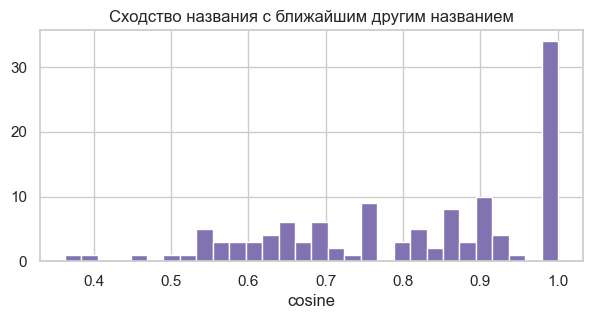

In [17]:
title_emb = embed(corpus.title)
sim = title_emb @ title_emb.T
np.fill_diagonal(sim, -1)
eval_pos = corpus.index[corpus.doc_id.isin(eval_set.relevant_doc_id)]
nearest = sim[eval_pos].max(axis=1)

print(f"Названий вида `О внесении изменений...`: {corpus.title.str.startswith('О внесении изменени').mean():.0%}")
print(f"Актов с полностью совпадающим названием у другого акта: {corpus.title.duplicated(keep=False).mean():.0%}")
print(f"Медианное сходство названия с ближайшим ДРУГИМ названием: {np.median(nearest):.3f}, "
      f"доля > 0.9: {(nearest > 0.9).mean():.0%}")
plt.figure(figsize=(7, 3)); plt.hist(nearest, bins=30, color="#8172B2")
plt.title("Сходство названия с ближайшим другим названием"); plt.xlabel("cosine"); plt.show()

### 6.2. Метрики

Для каждого запроса берём top-10 и считаем при k ∈ {1, 3, 5, 10}:
- **Recall@k** - доля релевантных чанков в top-k от всех чанков акта;
- **Precision@k** - доля релевантных среди k выданных;
- **MRR@k** - `1/rank` первого релевантного (0, если его нет в top-k);
- **Hit Rate@k** - есть ли в top-k хоть один чанк нужного акта;
- **nRecall@k** = найдено / `min(k, |релевантных|)` - Recall, нормированный на достижимый максимум. У длинного акта десятки чанков, и обычный Recall@k не может превысить `k / |релевантных|` даже при идеальной выдаче;
- среднее косинусное сходство **top-1** и **top-k** и **разрыв** `score(top-1) - score(top-k)`.

In [18]:
KS = [1, 3, 5, 10]


def metrics_for(results, rel_sets, with_scores=True):
    rows = []
    for res, rel in zip(results, rel_sets):
        rel = set(rel)
        hit = res.chunk_id.isin(rel).to_numpy()
        sc = res.score.to_numpy()
        for k in KS:
            h = hit[:k]
            first = int(np.argmax(h)) + 1 if h.any() else None
            row = {"k": k, "Recall": h.sum() / len(rel), "nRecall": h.sum() / min(k, len(rel)),
                   "Precision": h.sum() / k, "MRR": 1 / first if first else 0.0, "HitRate": float(h.any())}
            if with_scores:
                row |= {"sim_top1": sc[0], "sim_topk": sc[:k].mean(), "gap_top1_topk": sc[0] - sc[k - 1]}
            rows.append(row)
    return pd.DataFrame(rows).groupby("k").mean().T.round(3)


queries = eval_set["query"].tolist()
RESULTS = {name: retrieve_many(queries, 10, name) for name in CHUNKS}
TABLES = {name: metrics_for(RESULTS[name], eval_set[f"relevant_chunk_ids_{name}"]) for name in CHUNKS}
RESULTS["hybrid"] = [retrieve_hybrid(q, 10) for q in queries]
TABLES["hybrid"] = metrics_for(RESULTS["hybrid"], eval_set["relevant_chunk_ids_py"], with_scores=False)

for name, title in [("py", "Python-чанкинг (структура акта)"), ("lc", "RecursiveCharacterTextSplitter"),
                    ("hybrid", "Python-чанкинг + гибрид BM25/dense (RRF)")]:
    display(Markdown(f"**{title}**")); display(TABLES[name])

**Python-чанкинг (структура акта)**

k,1,3,5,10
Recall,0.062,0.126,0.143,0.176
nRecall,0.675,0.458,0.367,0.294
Precision,0.675,0.456,0.350,0.239
MRR,0.675,0.731,0.741,0.745
HitRate,0.675,0.792,0.833,0.867
sim_top1,0.817,0.817,0.817,0.817
sim_topk,0.817,0.765,0.736,0.692
gap_top1_topk,0.000,0.096,0.134,0.185


**RecursiveCharacterTextSplitter**

k,1,3,5,10
Recall,0.068,0.124,0.151,0.179
nRecall,0.650,0.410,0.349,0.284
Precision,0.650,0.400,0.320,0.221
MRR,0.650,0.701,0.715,0.720
HitRate,0.650,0.767,0.825,0.867
sim_top1,0.795,0.795,0.795,0.795
sim_topk,0.795,0.748,0.719,0.680
gap_top1_topk,0.000,0.088,0.126,0.169


**Python-чанкинг + гибрид BM25/dense (RRF)**

k,1,3,5,10
Recall,0.067,0.131,0.155,0.191
nRecall,0.733,0.483,0.394,0.313
Precision,0.733,0.481,0.375,0.252
MRR,0.733,0.778,0.782,0.787
HitRate,0.733,0.833,0.850,0.883


### 6.3. Сравнение стратегий

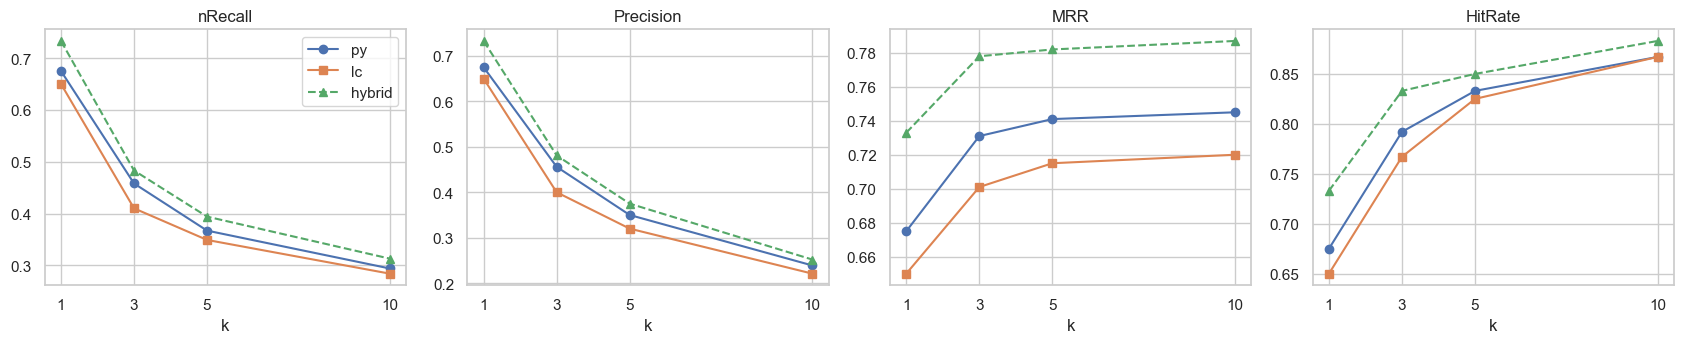

In [19]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for i, metric in enumerate(["nRecall", "Precision", "MRR", "HitRate"]):
    for name, style in [("py", "o-"), ("lc", "s-"), ("hybrid", "^--")]:
        ax[i].plot(KS, TABLES[name].loc[metric], style, label=name)
    ax[i].set_title(metric); ax[i].set_xticks(KS); ax[i].set_xlabel("k")
ax[0].legend(); plt.tight_layout(); plt.show()

**Сравнение стратегий.**
- **Python-чанкинг по структуре акта** лучше на верхних позициях: Hit Rate@1 0.675 против 0.650, MRR@10 0.745 против 0.720, Precision@5 0.350 против 0.320. Чанк не пересекает границу статьи, а первый раздел содержит название и преамбулу акта - этот чанк и находится по названию. Выше и уверенность индекса: sim(top-1) 0.817 против 0.795, разрыв top-1 - top-10 0.185 против 0.169.
- **RecursiveCharacterTextSplitter** даёт чанки чуть длиннее (~106 слов против ~97) и меньше их (16.4 тыс. против 19.3 тыс.), поэтому Recall@k у него на уровне Python-чанкинга при меньшей точности.
- **Гибрид BM25 + dense (RRF)** лучший по всем метрикам: Hit Rate@1 0.733, MRR@10 0.787, Hit Rate@10 0.883. Лексический поиск добавляет точные совпадения редких слов названия, которые плотный вектор `размывает`.
- Обычный **Recall@k** маленький у всех (0.14-0.19 при k=10) не из-за плохого поиска: у акта в среднем ~48 чанков (у 127-ФЗ - 675), и в top-10 физически не помещаются все. Нормированный nRecall показывает, что при k=1 в ~67-73% случаев первый результат из нужного акта.
- **Потолок < 1** задают сами данные: у 26% актов есть акт с полностью совпадающим названием (`О внесении изменений в отдельные законодательные акты Российской Федерации`), и по одному названию их не различить.

### Влияние очистки запроса

Берём 40 запросов набора и программно вносим опечатки: в словах длиной от 5 букв с вероятностью 0.35 (минимум одно слово на запрос) делаем замену, пропуск или перестановку соседних букв. Эталон известен, поэтому сравниваем Recall@5 и MRR@10 на трёх вариантах: исходный запрос, искажённый, искажённый после очистки. Кроме dense-поиска по обоим индексам смотрим чистый BM25 и гибрид - лексический поиск сравнивает слова буквально, и опечатка для него означает потерю слова.

In [20]:
CYR = "абвгдежзийклмнопрстуфхцчшщыьэюя"


def distort(text, rng, p=0.35):
    words = text.split()
    idx = [i for i, w in enumerate(words) if w.isalpha() and len(w) >= 5]
    chosen = [i for i in idx if rng.random() < p] or [rng.choice(idx)]
    for i in chosen:
        w = list(words[i]); j = rng.randrange(1, len(w) - 1)
        op = rng.choice(["replace", "delete", "swap"])
        if op == "replace":
            w[j] = rng.choice(CYR)
        elif op == "delete":
            del w[j]
        else:
            w[j], w[j + 1] = w[j + 1], w[j]
        words[i] = "".join(w)
    return " ".join(words)


rng = random.Random(RND)
typo_set = eval_set.sample(40, random_state=RND).reset_index(drop=True)
typo_set["noisy"] = [distort(q, rng) for q in typo_set["query"]]
typo_set["cleaned"] = [clean_query(q) for q in typo_set.noisy]
typo_set[["query", "noisy", "cleaned"]].head(6)

,query,noisy,cleaned
0,По делу о проверке конституционности отдельных положений подпункта 3 пункта 2 статьи 13 Федерального закон...,По делу о проверке конституционнцсти отдеьных полжжений подпункта 3 пункта 2 статьи 13 Федеравьного закона...,По делу о проверке конституционности отдельных положений подпункта 3 пункта 2 статьи 13 Федерального закон...
1,О внесении изменений в отдельные законодательные акты Российской Федерации,О внесенши изменений в отдельные законодательные акты Россиьской Фемерации,О внесении изменений в отдельные законодательные акты Российской Федерации
2,"Об утверждении разъяснения о вопросах, связанных с применением процедур банкротства","Об утеврждении разъяснения о вопросах, связанных с применением процедср банкоотства","Об утверждении разъяснения о вопросах, связанных с применением процедур банкротства"
3,"О порядке осуществления расчетов в целях погашения учредителями (участниками) должника, собственником имущ...","О порядке осуществления расчетов в целях погашения учредителями (участниками) должника, собственником имщу...","О порядке осуществления расчетов в целях погашения учредителями (участниками) должника, собственником имущ..."
4,"О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)""","О весении измеенний в Федеральный закон ""О несостоятельности (банкротстве)""","О внесении изменений в Федеральный закон ""О несостоятельности (банкротстве)"""
5,О внесении изменений в отдельные законодательные акты Российской Федерации и признании утратившим силу абз...,О внесении изменений в отдельные законодательные акты Росслйской Федерации и признании утратившим силу аба...,О внесении изменений в отдельные законодательные акты Российской Федерации и признании утратившим силу абз...


In [21]:
SEARCHERS = {"dense py": lambda qs: retrieve_many(qs, 10, "py"), "dense lc": lambda qs: retrieve_many(qs, 10, "lc"),
             "bm25 py": lambda qs: [retrieve_bm25(q, 10) for q in qs], "hybrid py": lambda qs: [retrieve_hybrid(q, 10) for q in qs]}
rows = {}
for variant in ["query", "noisy", "cleaned"]:
    for name, search in SEARCHERS.items():
        t = metrics_for(search(typo_set[variant].tolist()), typo_set[f"relevant_chunk_ids_{name[-2:]}"], with_scores=False)
        rows[(variant, name)] = {"Recall@5": t.loc["Recall", 5], "nRecall@5": t.loc["nRecall", 5],
                                 "HitRate@5": t.loc["HitRate", 5], "MRR@10": t.loc["MRR", 10]}
typo_table = pd.DataFrame(rows).T
typo_table.index = typo_table.index.set_names(["запрос", "поиск"])
typo_table = typo_table.unstack(0).swaplevel(axis=1).reindex(columns=["query", "noisy", "cleaned"], level=0)
restored = np.mean([c.lower() == q.lower() for c, q in zip(typo_set.cleaned, typo_set["query"])])
print(f"Запросов, восстановленных очисткой дословно: {restored:.0%}")
typo_table

Запросов, восстановленных очисткой дословно: 75%


запрос       query                               noisy                      \
          Recall@5 nRecall@5 HitRate@5 MRR@10 Recall@5 nRecall@5 HitRate@5   
поиск                                                                        
bm25 py      0.144     0.398     0.825  0.767    0.140     0.382     0.800   
dense lc     0.105     0.312     0.750  0.684    0.099     0.302     0.775   
dense py     0.097     0.328     0.800  0.706    0.097     0.303     0.750   
hybrid py    0.124     0.378     0.850  0.771    0.124     0.358     0.850   

запрос            cleaned                             
          MRR@10 Recall@5 nRecall@5 HitRate@5 MRR@10  
поиск                                                 
bm25 py    0.729    0.144     0.402     0.825  0.767  
dense lc   0.697    0.105     0.307     0.750  0.670  
dense py   0.661    0.097     0.328     0.800  0.694  
hybrid py  0.761    0.124     0.378     0.850  0.771

**Влияние очистки.**
- Плотный поиск `bge-m3` устойчив к опечаткам: модель режет слова на подслова, и искажённое слово остаётся близким к исходному. Recall@5 у dense почти не меняется, MRR@10 падает умеренно (Python-чанкинг: 0.706 -> 0.661), после очистки возвращается к 0.694.
- Сильнее всего опечатки бьют по **BM25**: MRR@10 0.767 -> 0.729, Hit Rate@5 0.825 -> 0.800 - искажённое слово для лексического поиска просто отсутствует. Очистка восстанавливает его метрики **полностью** (0.767 и 0.825).
- Гибрид почти не чувствует опечаток (MRR@10 0.771 -> 0.761 -> 0.771): одна из двух ветвей всегда находит документ.
- Очистка дословно восстановила 75% запросов. Остальные - случаи, когда опечатка дала существующую словоформу или другую форму того же слова; такие слова намеренно не трогаются, чтобы не портить грамматически правильные запросы (`водителю` не `исправляется` в `водителя`). Изредка исправление уводит в другое слово (dense lc: MRR@10 0.684 -> 0.670 после очистки), но в среднем очистка возвращает метрики к уровню исходных запросов.

## 7. Оценка генерации через RAGAS

### 7.1. Оценочный набор

22 вопроса генерируются синтетически: для случайных содержательных чанков (от 90 слов) LLM формулирует вопрос, на который фрагмент даёт однозначный ответ, и эталонный ответ только по этому фрагменту. Так известны и `ground_truth`, и эталонный контекст. Ещё 5 вопросов заведомо вне корпуса - для них правильный ответ это отказ. Набор кешируется в `data/ragas_questions.json`.

In [22]:
QGEN_PROMPT = """Ниже фрагмент нормативного акта. Сформулируй ОДИН конкретный вопрос, на который этот фрагмент даёт однозначный ответ, и короткий эталонный ответ (1-2 предложения) строго по фрагменту.
Вопрос должен быть понятен без фрагмента: назови предмет регулирования, не пиши `в данном фрагменте`, `в этом документе`.
Верни только JSON: {{"question": "...", "answer": "..."}}

Акт: {title} ({date})
Фрагмент: {text}"""

OUT_OF_CORPUS = [
    "Какой штраф грозит водителю за превышение скорости более чем на 40 км/ч?",
    "Какой срок действия водительского удостоверения в России?",
    "Как получить налоговый вычет за лечение зубов?",
    "Какие требования предъявляются к содержанию собак в многоквартирном доме?",
    "Какой минимальный размер оплаты труда установлен на 2026 год?",
]

Q_PATH = DATA / "ragas_questions.json"
if Q_PATH.exists():
    qa = pd.read_json(Q_PATH)
else:
    src = chunks_py[chunks_py.n_words >= 90].sample(22, random_state=RND)
    items = []
    for ch in src.itertuples():
        raw = chat([{"role": "user", "content": QGEN_PROMPT.format(title=ch.title, date=ch.date, text=ch.text)}])
        obj = json.loads(re.search(r"\{.*\}", raw, re.S).group(0))
        items.append({"question": obj["question"], "ground_truth": obj["answer"], "ref_chunk_id": ch.chunk_id,
                      "ref_doc_id": ch.doc_id, "in_corpus": True})
    items += [{"question": q, "ground_truth": NO_ANSWER, "ref_chunk_id": None, "ref_doc_id": None,
               "in_corpus": False} for q in OUT_OF_CORPUS]
    qa = pd.DataFrame(items)
    qa.to_json(Q_PATH, orient="records", force_ascii=False, indent=1)
print(f"Вопросов: {len(qa)}, из них вне корпуса: {(~qa.in_corpus).sum()}")
qa[["question", "ground_truth"]].head(6)

Вопросов: 27, из них вне корпуса: 5


,question,ground_truth
0,Какие документы должны прилагаться к плану добровольной ликвидации предприятия?,К плану прилагаются бухгалтерский баланс предприятия на момент принятия решения о добровольной ликвидации ...
1,"Какой документ необходим для государственной регистрации договора участия в долевом строительстве, заключё...",Необходимо разрешение на строительство. Заявитель вправе не представлять его: тогда орган регистрации прав...
2,"Когда может быть принято решение о созыве общего собрания акционеров негосударственного пенсионного фонда,...","Не ранее даты зачисления акций, размещённых в ходе дополнительного выпуска, на лицевой счёт в реестре влад..."
3,Как застройщик обязан вести учет денежных средств участников долевого строительства и затрат на строительс...,Застройщик обязан вести такой учет отдельно в отношении каждого многоквартирного дома и (или) иного объект...
4,"Какой орган осуществляет полномочия, которые в указанных положениях жилищного законодательства ранее были ...",Уполномоченный Правительством Российской Федерации федеральный орган исполнительной власти.
5,Кто обязан вносить сведения о заключении договора финансовой аренды (лизинга) в Единый федеральный реестр ...,Сведения обязан вносить лизингодатель.


### 7.2. Прогон конвейера и метрики RAGAS

Для каждого вопроса собираем четвёрку `question / contexts / answer / ground_truth` в четырёх конфигурациях (ablation): **без контекста** (чистая LLM), RAG с **top_k = 1 / 3 / 5**.

Метрики RAGAS (LLM-судья - та же `gpt-6-luna`, эмбеддинги для Answer relevancy - `text-embedding-3-small`):
- **Faithfulness** - доля утверждений ответа, подтверждаемых контекстом (обратное - галлюцинации);
- **Answer relevancy** - насколько ответ отвечает на вопрос (по сходству вопроса с вопросами, восстановленными из ответа);
- **Context precision** - релевантные фрагменты стоят выше нерелевантных;
- **Context recall** - доля утверждений эталона, которые можно найти в контексте.

Для вопросов вне корпуса отдельно считаем **abstention accuracy** (доля корректных отказов) и **hallucination rate** (доля содержательных ответов вместо отказа). Оценки кешируются в `data/ragas_scores.csv`.

In [23]:
CONFIGS = {"no_context": 0, "top1": 1, "top3": 3, "top5": 5}


def run_one(question, top_k):
    if top_k == 0:
        return {"question": question, "contexts": [], "answer": llm_only(question), "retrieved_docs": []}
    out = rag_answer(question, top_k)
    return {"question": question, "contexts": out["hits"].text.tolist(), "answer": out["answer"],
            "retrieved_docs": out["hits"].doc_id.tolist()}


def run_config(top_k):
    with ThreadPoolExecutor(8) as pool:
        return pd.DataFrame(pool.map(lambda q: run_one(q, top_k), qa.question))


RUNS = {name: run_config(k) for name, k in CONFIGS.items()}
RUNS["top5"][["question", "answer"]].head(3)

,question,answer
0,Какие документы должны прилагаться к плану добровольной ликвидации предприятия?,К плану добровольной ликвидации прилагаются бухгалтерский баланс предприятия на момент принятия решения о ...
1,"Какой документ необходим для государственной регистрации договора участия в долевом строительстве, заключё...",Для регистрации договора с первым участником необходимо разрешение на строительство; заявитель вправе его ...
2,"Когда может быть принято решение о созыве общего собрания акционеров негосударственного пенсионного фонда,...","Когда может быть принято решение о созыве общего собрания, в найденных фрагментах не указано. Указано лишь..."


In [24]:
from ragas.llms import llm_factory
from ragas.embeddings import embedding_factory
from ragas.metrics.collections import Faithfulness, AnswerRelevancy, ContextPrecision, ContextRecall

aclient = AsyncOpenAI(base_url=os.environ["LLM_BASE_URL"], api_key=os.environ["LLM_API_KEY"])
judge = llm_factory(LLM_MODEL, client=aclient, max_tokens=4000)
judge_emb = embedding_factory("openai", model="text-embedding-3-small", client=aclient)
M = {"faithfulness": Faithfulness(llm=judge), "answer_relevancy": AnswerRelevancy(llm=judge, embeddings=judge_emb),
     "context_precision": ContextPrecision(llm=judge), "context_recall": ContextRecall(llm=judge)}
SCORES_PATH = DATA / "ragas_scores.csv"
SEM = asyncio.Semaphore(4)


def job_key(config, i, metric):
    r = RUNS[config].iloc[i]
    return hashlib.md5(json.dumps([config, metric, r.question, r.answer, r.contexts], ensure_ascii=False).encode()).hexdigest()


async def score_one(config, i, metric, key):
    r, g = RUNS[config].iloc[i], qa.iloc[i]
    kw = {"faithfulness": dict(user_input=r.question, response=r.answer, retrieved_contexts=r.contexts),
          "answer_relevancy": dict(user_input=r.question, response=r.answer),
          "context_precision": dict(user_input=r.question, reference=g.ground_truth, retrieved_contexts=r.contexts),
          "context_recall": dict(user_input=r.question, retrieved_contexts=r.contexts, reference=g.ground_truth)}[metric]
    async with SEM:
        for attempt in range(5):                                 # шлюз иногда отвечает 503 - ждём и повторяем
            try:
                return {"key": key, "config": config, "i": i, "metric": metric, "value": (await M[metric].ascore(**kw)).value}
            except Exception:
                await asyncio.sleep(5 * 2 ** attempt)
    return {"key": key, "config": config, "i": i, "metric": metric, "value": np.nan}


def jobs():
    for config in CONFIGS:
        for i, g in qa.iterrows():
            if not g.in_corpus:                                  # вне корпуса - только faithfulness для галлюцинаций
                if config != "no_context":
                    yield config, i, "faithfulness"
                continue
            yield config, i, "answer_relevancy"
            if config != "no_context":                           # без контекста context-метрики не определены
                yield from ((config, i, m) for m in ("faithfulness", "context_precision", "context_recall"))


KEYS = {j: job_key(*j) for j in jobs()}
done = pd.read_csv(SCORES_PATH) if SCORES_PATH.exists() else pd.DataFrame(columns=["key", "config", "i", "metric", "value"])
done = done[done.key.isin(KEYS.values()) & done.value.notna()]          # оценки устаревших ответов отбрасываем
todo = [j for j, k in KEYS.items() if k not in set(done.key)]
if todo:
    t = time.time()
    new = await asyncio.gather(*(score_one(*j, KEYS[j]) for j in todo))
    done = pd.concat([d for d in (done, pd.DataFrame(new)) if len(d)], ignore_index=True)
    done.to_csv(SCORES_PATH, index=False)
    print(f"оценено {len(todo)} пар за {time.time() - t:.0f} с, не удалось: {done.value.isna().sum()}")
scores = done.merge(qa[["in_corpus"]], left_on="i", right_index=True)

C:\Users\Георгий\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\api_core\_python_version_support.py:266: FutureWarning: You are using a Python version (3.11.4) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


C:\Users\Георгий\AppData\Local\Temp\ipykernel_3268\3159189637.py:7: DeprecationWarning: Importing embedding_factory from ragas.embeddings is deprecated. Import directly from ragas.embeddings.base or use modern providers: from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  judge_emb = embedding_factory("openai", model="text-embedding-3-small", client=aclient)


оценено 301 пар за 1245 с, не удалось: 0


### 7.3. Результаты и ablation по размеру контекста

metric,answer_relevancy,context_precision,context_recall,faithfulness
config,,,,
no_context,0.650,NaN,NaN,NaN
top1,0.579,0.727,0.727,0.909
top3,0.731,0.761,0.864,0.841
top5,0.715,0.759,0.909,1.000


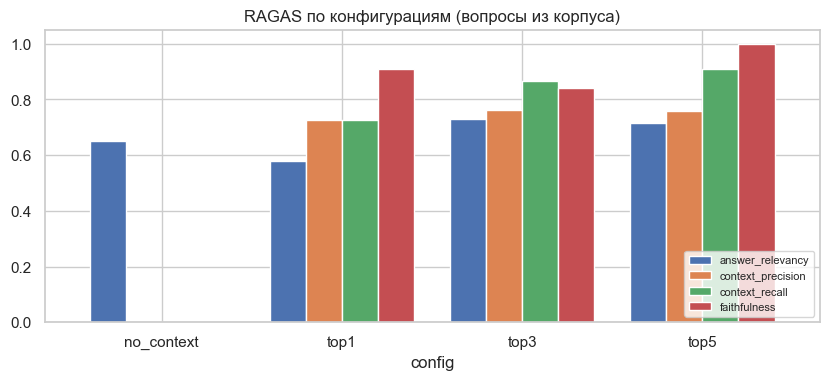

In [25]:
ragas_table = (scores[scores.in_corpus].pivot_table(index="config", columns="metric", values="value", aggfunc="mean")
               .reindex(list(CONFIGS)).round(3))
display(ragas_table)

ax = ragas_table.plot.bar(figsize=(10, 3.8), rot=0, width=0.8)
ax.set_ylim(0, 1.05); ax.set_title("RAGAS по конфигурациям (вопросы из корпуса)")
ax.legend(loc="lower right", fontsize=8); plt.show()

### Вопросы без ответа в корпусе: отказ и галлюцинации

Отказ засчитывается, если ответ содержит фразу `Информация в найденных статьях отсутствует`. Галлюцинация - содержательный ответ вместо отказа. Для сравнения считаем то же для `чистой` LLM и долю ложных отказов на вопросах, ответ на которые в корпусе есть.

In [26]:
def is_refusal(text):
    return "информация в найденных статьях отсутствует" in text.lower()


rows = []
for config in CONFIGS:
    ans = RUNS[config].answer.map(is_refusal)
    rows.append({"config": config,
                 "abstention_accuracy": ans[~qa.in_corpus].mean(),
                 "hallucination_rate": 1 - ans[~qa.in_corpus].mean(),
                 "false_refusal_rate": ans[qa.in_corpus].mean()})
abst = pd.DataFrame(rows).set_index("config").round(3)
display(abst)
for q, a in zip(qa.question[~qa.in_corpus], RUNS["top5"].answer[~qa.in_corpus]):
    print(f"- {q}\n  -> {a[:150]}")

,abstention_accuracy,hallucination_rate,false_refusal_rate
config,,,
no_context,0.0,1.0,0.000
top1,1.0,0.0,0.136
top3,1.0,0.0,0.045
top5,1.0,0.0,0.045


- Какой штраф грозит водителю за превышение скорости более чем на 40 км/ч?
  -> Информация в найденных статьях отсутствует
- Какой срок действия водительского удостоверения в России?
  -> Информация в найденных статьях отсутствует
- Как получить налоговый вычет за лечение зубов?
  -> Информация в найденных статьях отсутствует
- Какие требования предъявляются к содержанию собак в многоквартирном доме?
  -> Информация в найденных статьях отсутствует
- Какой минимальный размер оплаты труда установлен на 2026 год?
  -> Информация в найденных статьях отсутствует


### Связь качества поиска и качества ответа

Проверяем тезис `хороший retrieval -> хороший ответ`: делим вопросы (top5) на те, где эталонный чанк попал в контекст, и те, где не попал, и сравниваем метрики RAGAS.

In [27]:
top5 = RUNS["top5"].copy()
top5["ref_found"] = [rc in chunks_py.chunk_id[chunks_py.text.isin(ctx)].values
                     for rc, ctx in zip(qa.ref_chunk_id, top5.contexts)]
top5["doc_found"] = [rd in docs for rd, docs in zip(qa.ref_doc_id, top5.retrieved_docs)]
s5 = scores[(scores.config == "top5") & scores.in_corpus].pivot(index="i", columns="metric", values="value")
s5 = s5.join(top5[["ref_found", "doc_found"]])
print(f"Эталонный чанк в top-5: {s5.ref_found.mean():.0%}, эталонный акт в top-5: {s5.doc_found.mean():.0%}")
s5.groupby("ref_found")[list(M)].mean().round(3)

Эталонный чанк в top-5: 86%, эталонный акт в top-5: 100%


,faithfulness,answer_relevancy,context_precision,context_recall
ref_found,,,,
False,1.0,0.427,0.583,0.333
True,1.0,0.760,0.787,1.000


**Ablation по размеру контекста.**
- **Context recall** растёт с k: 0.727 -> 0.864 -> 0.909. Чем больше фрагментов, тем чаще среди них есть эталонный.
- **Context precision** почти не меняется (0.727 -> 0.761 -> 0.759): лишние фрагменты в основном стоят ниже релевантного и не `топят` его.
- **Answer relevancy** максимальна при top-3 (0.731). При top-1 она проседает до 0.579 из-за ложных отказов: если единственный фрагмент не тот, модель честно отвечает `информация отсутствует` (13.6% вопросов против 4.5% при top-3/5). При top-5 relevancy чуть ниже, чем при top-3 (0.715): ответ обрастает оговорками из соседних фрагментов.
- **Faithfulness** высокая во всех RAG-конфигурациях (0.84-1.0): модель держится контекста. Колебания между конфигурациями в пределах шума LLM-судьи на выборке из 22 вопросов.
- Ответы **без контекста** по relevancy (0.650) сопоставимы с RAG - модель отвечает `по теме`, но проверить их нечем, а на вопросах вне корпуса она в 100% случаев выдаёт содержательный ответ вместо отказа (hallucination rate 1.0). RAG при любом k корректно отказывается во всех 5 случаях (abstention accuracy 1.0).

**Согласуется ли с п. 6.** Да. Эталонный акт найден в top-5 для 100% вопросов, эталонный чанк - для 86% (близко к Hit Rate@5 0.83 из п. 6). Когда эталонный чанк в контексте, context recall 1.0 и answer relevancy 0.76; когда его нет - context recall 0.33 и relevancy 0.43, при этом faithfulness остаётся 1.0: модель не выдумывает недостающее, а отвечает частично или отказывается. Хороший retrieval - необходимое условие хорошего ответа, а строгий промпт не даёт плохому retrieval превратиться в галлюцинацию.

## Выводы

- Собран корпус из **410 нормативных актов** по банкротству (1990-2026, ~1.6 млн слов) из открытого датасета RusLawOD (pravo.gov.ru): чтение по сети только нужных колонок, повторы с экспоненциальной паузой, кеш сырой выборки и структурированный `corpus.jsonl` с метаданными.
- Реализованы две стратегии чанкинга с окном ~140 слов и перекрытием ~25: структурная (по статьям и пунктам акта, скользящее окно по предложениям) - 19.3 тыс. чанков, и `RecursiveCharacterTextSplitter` - 16.4 тыс. У каждого чанка метаданные акта: `doc_id`, название, орган, дата, ссылка.
- Эмбеддинги доменной моделью `bge-m3-legal-ru` (1024, L2-нормализация), точные индексы FAISS `IndexFlatIP` для каждой стратегии, функция `retrieve` с косинусным сходством; дополнительно - гибрид BM25 + dense через RRF.
- Очистка запроса (SymSpell по словарю корпуса + защита номеров статей, аббревиатур и словоформ + расшифровка сокращений) полностью возвращает качество лексического поиска на запросах с опечатками; dense-поиск к опечаткам устойчив сам.
- Offline-оценка на 120 запросах: структурный чанкинг лучше LangChain на верхних позициях (MRR@10 0.745 против 0.720), гибрид - лучший (MRR@10 0.787, Hit Rate@10 0.883). Предел качества задают однотипные названия актов (26% названий повторяются дословно).
- LLM `gpt-6-luna` со строгим промптом отвечает только по контексту со ссылками `[n]` на акты. RAGAS: faithfulness 0.84-1.0, context recall растёт с top-k до 0.91, лучший баланс при top-3. На вопросах вне корпуса RAG отказывается в 100% случаев, а LLM без контекста в 100% случаев отвечает `по памяти`.
- Хороший retrieval напрямую ведёт к хорошему ответу (relevancy 0.76 против 0.43, context recall 1.0 против 0.33), а при плохом retrieval модель не галлюцинирует, а отвечает частично или отказывается.